# UPI Transactions Analysis

In this project, I explored a synthetic dataset of 250,000 UPI transactions from 2024 using Python.

The main questions I wanted to explore were:

1. How do transaction amounts vary across age groups and merchant categories?
2. How do fraud-flag counts and rates differ across merchant categories?
3. Which age groups contribute the most transaction value across merchant categories?
4. What patterns can be observed in fraud flags over time?
5. How do transaction failure rates vary by device, network, transaction type, and time?

Since the dataset is synthetically generated, the findings describe this dataset and should not be treated as real-world UPI trends.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set_theme(style="whitegrid", palette="muted")

In [3]:
df = pd.read_csv("upi_transactions_2024.csv")
df

,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,TXN0000249996,2024-11-08 22:41:43,Recharge,Food,373,SUCCESS,36-45,26-35,Telangana,ICICI,HDFC,iOS,5G,0,22,Friday,0
249996,TXN0000249997,2024-12-15 02:58:03,P2P,Utilities,2025,SUCCESS,36-45,26-35,Rajasthan,HDFC,Yes Bank,Android,5G,0,2,Sunday,1
249997,TXN0000249998,2024-11-27 16:33:25,P2P,Food,468,SUCCESS,26-35,18-25,West Bengal,ICICI,ICICI,Android,4G,0,16,Wednesday,0
249998,TXN0000249999,2024-01-05 13:31:30,Recharge,Healthcare,284,SUCCESS,18-25,36-45,Andhra Pradesh,Axis,ICICI,iOS,4G,0,13,Friday,0


In [4]:
df.columns

Index(['transaction id', 'timestamp', 'transaction type', 'merchant_category',
       'amount (INR)', 'transaction_status', 'sender_age_group',
       'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank',
       'device_type', 'network_type', 'fraud_flag', 'hour_of_day',
       'day_of_week', 'is_weekend'],
      dtype='object')

In [5]:
df.describe()

,amount (INR),fraud_flag,hour_of_day,is_weekend
count,250000.000000,250000.000000,250000.000000,250000.000000
mean,1311.756036,0.001920,14.681032,0.285348
std,1848.059224,0.043776,5.188304,0.451581
min,10.000000,0.000000,0.000000,0.000000
25%,288.000000,0.000000,11.000000,0.000000
50%,629.000000,0.000000,15.000000,0.000000
75%,1596.000000,0.000000,19.000000,1.000000
max,42099.000000,1.000000,23.000000,1.000000


In [6]:
df.dtypes

transaction id        object
timestamp             object
transaction type      object
merchant_category     object
amount (INR)           int64
transaction_status    object
sender_age_group      object
receiver_age_group    object
sender_state          object
sender_bank           object
receiver_bank         object
device_type           object
network_type          object
fraud_flag             int64
hour_of_day            int64
day_of_week           object
is_weekend             int64
dtype: object

In [7]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df.dtypes

transaction id                object
timestamp             datetime64[ns]
transaction type              object
merchant_category             object
amount (INR)                   int64
transaction_status            object
sender_age_group              object
receiver_age_group            object
sender_state                  object
sender_bank                   object
receiver_bank                 object
device_type                   object
network_type                  object
fraud_flag                     int64
hour_of_day                    int64
day_of_week                   object
is_weekend                     int64
dtype: object

In [8]:
df['transaction id'].isna().sum()

np.int64(0)

In [9]:
df['transaction id'].duplicated().sum()

np.int64(0)

In [10]:
df.isnull().sum()

transaction id        0
timestamp             0
transaction type      0
merchant_category     0
amount (INR)          0
transaction_status    0
sender_age_group      0
receiver_age_group    0
sender_state          0
sender_bank           0
receiver_bank         0
device_type           0
network_type          0
fraud_flag            0
hour_of_day           0
day_of_week           0
is_weekend            0
dtype: int64

In [11]:
df.shape

(250000, 17)

In [12]:
df["transaction_status"].value_counts()

transaction_status
SUCCESS    237624
FAILED      12376
Name: count, dtype: int64

In [13]:
df["transaction type"].value_counts()

transaction type
P2P             112445
P2M              87660
Bill Payment     37368
Recharge         12527
Name: count, dtype: int64

In [14]:
df["merchant_category"].value_counts()

merchant_category
Grocery          49966
Food             37464
Shopping         29872
Fuel             25063
Other            24828
Utilities        22338
Transport        20105
Entertainment    20103
Healthcare       12663
Education         7598
Name: count, dtype: int64

In [15]:
df["sender_age_group"].value_counts()

sender_age_group
26-35    87432
36-45    62873
18-25    62345
46-55    24841
56+      12509
Name: count, dtype: int64

In [16]:
df["sender_state"].value_counts()

sender_state
Maharashtra       37427
Uttar Pradesh     30125
Karnataka         29756
Tamil Nadu        25367
Delhi             24870
Telangana         22435
Gujarat           20061
Andhra Pradesh    20006
Rajasthan         19981
West Bengal       19972
Name: count, dtype: int64

In [17]:
df["amount (INR)"].describe()

count    250000.000000
mean       1311.756036
std        1848.059224
min          10.000000
25%         288.000000
50%         629.000000
75%        1596.000000
max       42099.000000
Name: amount (INR), dtype: float64

In [18]:
bins = range(0, 45001, 500)

amount_distribution = pd.cut(df["amount (INR)"], bins=bins, right=False).value_counts().sort_index()

distribution_table = pd.DataFrame({"Transaction Count": amount_distribution, "Percentage": amount_distribution / len(df) * 100})

distribution_table

,Transaction Count,Percentage
amount (INR),,
"[0, 500)",106462,42.5848
"[500, 1000)",51135,20.4540
"[1000, 1500)",26027,10.4108
"[1500, 2000)",17192,6.8768
"[2000, 2500)",12262,4.9048
...,...,...
"[42500, 43000)",0,0.0000
"[43000, 43500)",0,0.0000
"[43500, 44000)",0,0.0000


Text(0, 0.5, 'Number of Transactions')

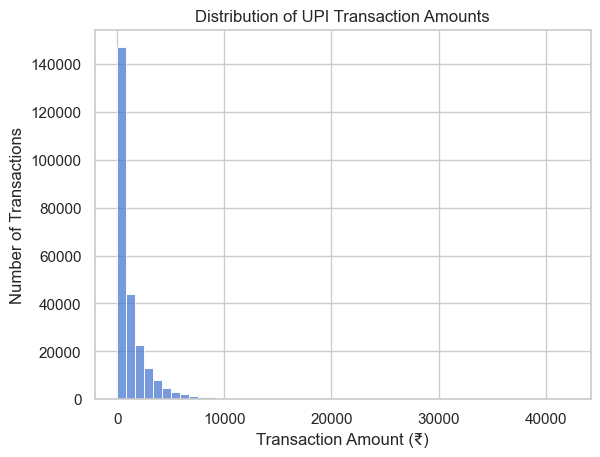

In [19]:
sns.histplot(data=df, x="amount (INR)", bins = 50)
plt.title("Distribution of UPI Transaction Amounts")
plt.xlabel("Transaction Amount (₹)")
plt.ylabel("Number of Transactions")

Text(0, 0.5, 'Number of Transactions')

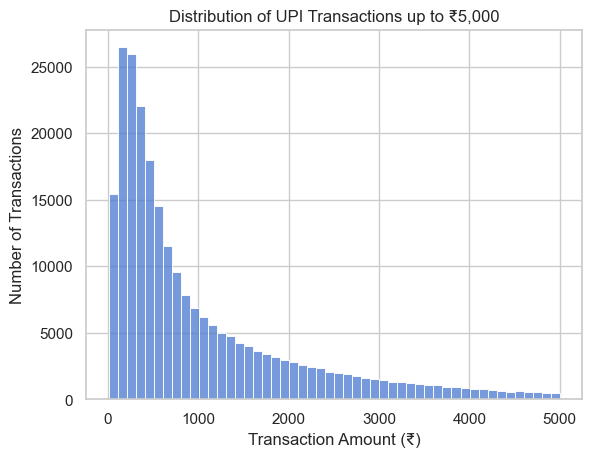

In [20]:
sns.histplot(data=df[df['amount (INR)']<=5000], x="amount (INR)", bins=50)
plt.title("Distribution of UPI Transactions up to ₹5,000")
plt.xlabel("Transaction Amount (₹)")
plt.ylabel("Number of Transactions")

## Observation

The transaction amount distribution is right-skewed, indicating that lower-value transactions occur more frequently than higher-value transactions. Most transactions are concentrated at relatively small amounts, while a smaller number of high-value transactions extend the distribution's upper tail.

This suggests that transaction amounts vary considerably, so the mean alone may not fully represent a typical transaction.

In [21]:
pd.crosstab(df['transaction type'],df['transaction_status'], normalize ="index")*100

transaction_status,FAILED,SUCCESS
transaction type,,
Bill Payment,4.881182,95.118818
P2M,4.949806,95.050194
P2P,4.957979,95.042021
Recharge,5.092999,94.907001


In [22]:
failure_rates = (pd.crosstab(df['transaction type'],df['transaction_status'], normalize ="index")["FAILED"]*100).sort_values(ascending=False)
failure_rates

transaction type
Recharge        5.092999
P2P             4.957979
P2M             4.949806
Bill Payment    4.881182
Name: FAILED, dtype: float64

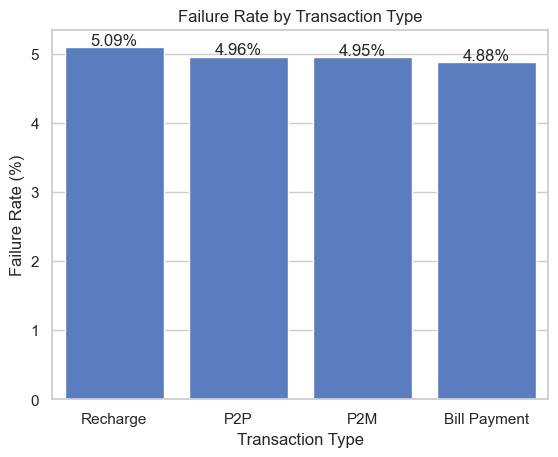

In [23]:
sns.barplot(x=failure_rates.index,y=failure_rates.values)
plt.title("Failure Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Failure Rate (%)")

for i, value in enumerate(failure_rates.values):
    plt.text(i, value + 0.03, f"{value:.2f}%",
             ha="center")

## Observation

Approximately 4.95% of transactions failed, while 95.05% were successful. Failure rates were relatively similar across transaction types, hours of the day, and weekdays versus weekends.

The weekend failure rate (5.09%) was slightly higher than the weekday rate (4.89%), a difference of approximately 0.20 percentage points. These are descriptive comparisons and do not establish the causes of transaction failures.

In [24]:
df["fraud_flag"].value_counts()

fraud_flag
0    249520
1       480
Name: count, dtype: int64

In [25]:
df["fraud_flag"].value_counts(normalize=True) * 100

fraud_flag
0    99.808
1     0.192
Name: proportion, dtype: float64

In [26]:
fraud_by_category = df.groupby("merchant_category")['fraud_flag'].agg(Fraud_flagged="sum",Total_Transactions="count",**{"Fraud Rate (%)":lambda x: x.mean()*100}).sort_values("Fraud Rate (%)", ascending=False)
fraud_by_category

,Fraud_flagged,Total_Transactions,Fraud Rate (%)
merchant_category,,,
Transport,43,20105,0.213877
Education,16,7598,0.210582
Shopping,62,29872,0.207552
Other,50,24828,0.201386
Entertainment,40,20103,0.198975
Food,73,37464,0.194854
Fuel,48,25063,0.191517
Grocery,94,49966,0.188128
Healthcare,21,12663,0.165837


Text(0.5, 1.0, 'Fraud flag Rate by merchant category')

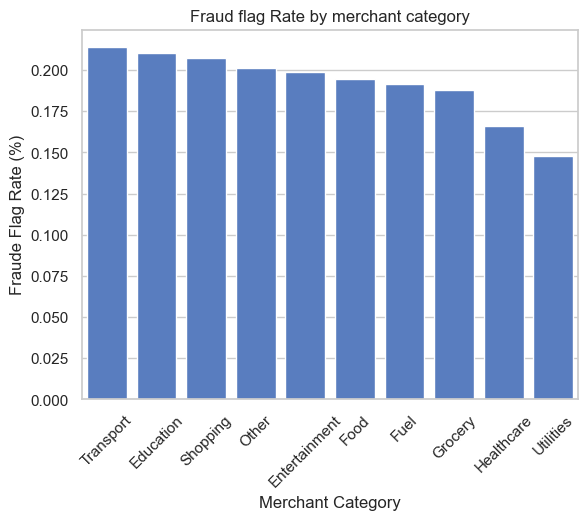

In [27]:
sns.barplot(data=fraud_by_category.reset_index(), x="merchant_category",y="Fraud Rate (%)")
plt.xticks(rotation=45)
plt.xlabel("Merchant Category")
plt.ylabel("Fraude Flag Rate (%)")
plt.title("Fraud flag Rate by merchant category")

In [28]:
fraud_count = fraud_by_category.sort_values("Fraud_flagged",ascending=False)
fraud_count

,Fraud_flagged,Total_Transactions,Fraud Rate (%)
merchant_category,,,
Grocery,94,49966,0.188128
Food,73,37464,0.194854
Shopping,62,29872,0.207552
Other,50,24828,0.201386
Fuel,48,25063,0.191517
Transport,43,20105,0.213877
Entertainment,40,20103,0.198975
Utilities,33,22338,0.147730
Healthcare,21,12663,0.165837


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Grocery'),
  Text(1, 0, 'Food'),
  Text(2, 0, 'Shopping'),
  Text(3, 0, 'Other'),
  Text(4, 0, 'Fuel'),
  Text(5, 0, 'Transport'),
  Text(6, 0, 'Entertainment'),
  Text(7, 0, 'Utilities'),
  Text(8, 0, 'Healthcare'),
  Text(9, 0, 'Education')])

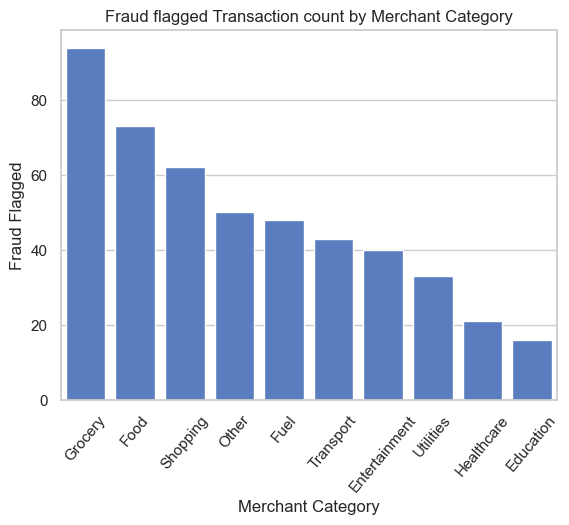

In [29]:
sns.barplot(data=fraud_count, x= "merchant_category",y="Fraud_flagged")
plt.title("Fraud flagged Transaction count by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Fraud Flagged")
plt.xticks(rotation=50)

## Observation

Approximately 0.192% of transactions were marked with a fraud flag. Transport had the highest fraud-flag rate among merchant categories, while Grocery had the highest number of flagged transactions.

However, the dataset's fraud flags are randomly generated rather than based on verified fraud cases. These results therefore describe the simulated labels and should not be interpreted as evidence of actual UPI fraud patterns.

In [30]:
df.columns

Index(['transaction id', 'timestamp', 'transaction type', 'merchant_category',
       'amount (INR)', 'transaction_status', 'sender_age_group',
       'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank',
       'device_type', 'network_type', 'fraud_flag', 'hour_of_day',
       'day_of_week', 'is_weekend'],
      dtype='object')

In [31]:
df.groupby("sender_age_group")['amount (INR)'].agg(["sum","count","mean"]).sort_values("sum",ascending=False)

,sum,count,mean
sender_age_group,,,
26-35,115959771,87432,1326.285239
36-45,89533745,62873,1424.041242
18-25,74473936,62345,1194.545449
46-55,33116261,24841,1333.129141
56+,14855296,12509,1187.568631


In [32]:
age_category = df.groupby(['sender_age_group','merchant_category'])['amount (INR)'].sum().reset_index()
age_category

,sender_age_group,merchant_category,amount (INR)
0,18-25,Education,5975262
1,18-25,Entertainment,2472467
2,18-25,Food,5349000
3,18-25,Fuel,8670515
4,18-25,Grocery,11834486
5,18-25,Healthcare,1057729
6,18-25,Other,5691302
7,18-25,Shopping,22877040
8,18-25,Transport,1734166
9,18-25,Utilities,8811969


In [33]:
age_category_pivot = age_category.pivot(index="sender_age_group",columns="merchant_category", values="amount (INR)")
age_category_pivot

merchant_category,Education,Entertainment,Food,Fuel,Grocery,Healthcare,Other,Shopping,Transport,Utilities
sender_age_group,,,,,,,,,,
18-25,5975262,2472467,5349000,8670515,11834486,1057729,5691302,22877040,1734166,8811969
26-35,13757322,3107354,7365531,13376810,20589919,2056767,7554490,28310939,2191894,17648745
36-45,13198094,1866565,4628046,11395137,16853952,2015922,5188137,17217294,1473606,15696992
46-55,4389855,605017,1756995,4003156,6233102,966820,1840867,5978073,584008,6758368
56+,1383813,257677,819830,1536957,2766434,776921,798653,2479861,208742,3826408


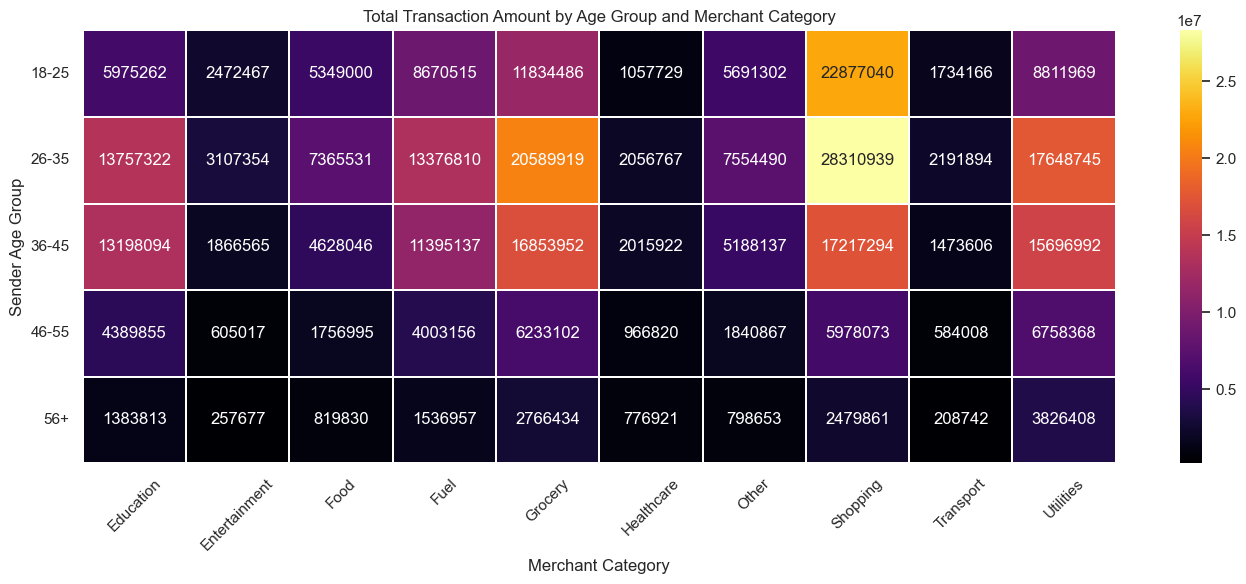

In [59]:
plt.figure(figsize=(14, 6))
sns.heatmap(data=age_category_pivot,cmap="inferno",annot=True,linewidths=0.3,fmt=".0f",)
plt.title("Total Transaction Amount by Age Group and Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Sender Age Group")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()

## Observation

Shopping accounts for the highest total transaction amount among the 18–25, 26–35, and 36–45 age groups. For the 46–55 and 56+ groups, Utilities records the highest total transaction amount.

These figures represent aggregate transaction amounts, not individual spending preferences or average spending per person. Since the dataset is synthetic and its amount-generation function explicitly applies age-group and merchant-category multipliers, these patterns may reflect the generator's assumptions rather than real-world consumer behavior.

In [34]:
df.columns

Index(['transaction id', 'timestamp', 'transaction type', 'merchant_category',
       'amount (INR)', 'transaction_status', 'sender_age_group',
       'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank',
       'device_type', 'network_type', 'fraud_flag', 'hour_of_day',
       'day_of_week', 'is_weekend'],
      dtype='object')

In [35]:
hourly_failure = pd.crosstab(df['hour_of_day'],df['transaction_status'], normalize="index")*100
hourly_failure

transaction_status,FAILED,SUCCESS
hour_of_day,,
0,5.371901,94.628099
1,5.347594,94.652406
2,5.163205,94.836795
3,5.022831,94.977169
4,5.132318,94.867682
5,4.535017,95.464983
6,5.398458,94.601542
7,4.884547,95.115453
8,5.006588,94.993412


In [36]:
hourly_failure["FAILED"].idxmin()

np.int64(5)

In [37]:
hourly_failure["FAILED"].idxmax()

np.int64(6)

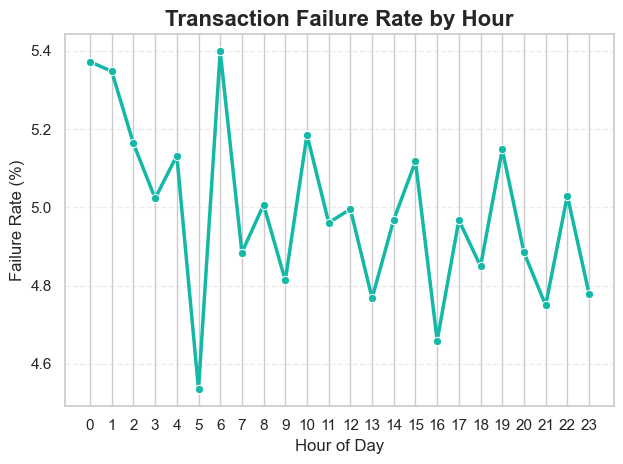

In [58]:
sns.lineplot(data=hourly_failure["FAILED"],linewidth=2.5,color = "#14B8A6", marker="o", markersize=6)
plt.title("Transaction Failure Rate by Hour", fontsize=16,fontweight="bold")
plt.xlabel("Hour of Day", fontsize=12)
plt.ylabel("Failure Rate (%)", fontsize=12)
plt.xticks(range(0,24))
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

## Observation

Transaction failure rates varied from approximately 4.54% at 5 AM to 5.40% at 6 AM. However, the rates remained close to 5% throughout the day.

Since transaction status is randomly assigned in this synthetic dataset, these differences do not establish real-world hourly failure patterns or explain why transactions fail.

In [39]:
df.columns

Index(['transaction id', 'timestamp', 'transaction type', 'merchant_category',
       'amount (INR)', 'transaction_status', 'sender_age_group',
       'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank',
       'device_type', 'network_type', 'fraud_flag', 'hour_of_day',
       'day_of_week', 'is_weekend'],
      dtype='object')

In [40]:
weekend_failure = pd.crosstab(df['is_weekend'],df['transaction_status'],normalize="index")*100
weekend_failure

transaction_status,FAILED,SUCCESS
is_weekend,,
0,4.894130,95.105870
1,5.091327,94.908673


In [41]:
weekend_analysis =  df.groupby("is_weekend")['transaction_status'].agg(Total_Transactions='count',Failed_Transactions=lambda x: (x=="FAILED").sum())
weekend_analysis

,Total_Transactions,Failed_Transactions
is_weekend,,
0,178663,8744
1,71337,3632


In [42]:
weekend_analysis["Failed_Transactions_(%)"] = weekend_analysis['Failed_Transactions'] / weekend_analysis['Total_Transactions'] * 100
weekend_analysis

,Total_Transactions,Failed_Transactions,Failed_Transactions_(%)
is_weekend,,,
0,178663,8744,4.894130
1,71337,3632,5.091327


In [43]:
weekend_analysis.index = ['weekdays','weekends']
weekend_analysis

,Total_Transactions,Failed_Transactions,Failed_Transactions_(%)
weekdays,178663,8744,4.894130
weekends,71337,3632,5.091327


Text(0, 0.5, 'Failure Rate (%)')

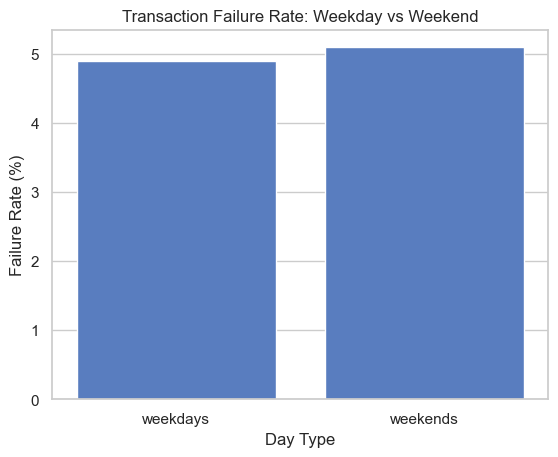

In [44]:
sns.barplot(data=weekend_analysis.reset_index(), x="index", y="Failed_Transactions_(%)")
plt.title("Transaction Failure Rate: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Failure Rate (%)")

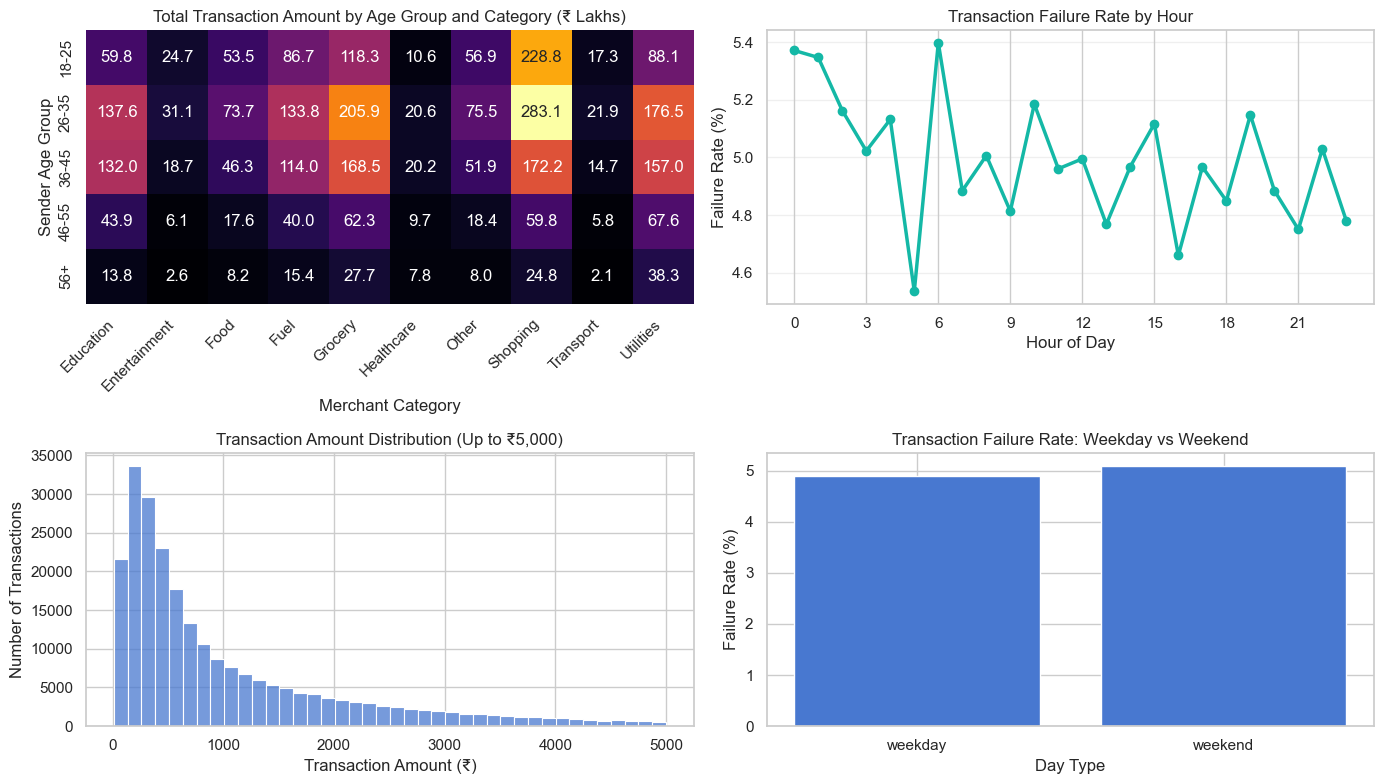

In [90]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.heatmap(age_category_pivot/100000,cmap="inferno",annot=True,fmt=".1f",ax=axes[0, 0],cbar=False)
axes[0, 0].set_title("Total Transaction Amount by Age Group and Category (₹ Lakhs)")
axes[0, 0].set_xlabel("Merchant Category")
axes[0, 0].set_ylabel("Sender Age Group")
axes[0,0].set_xticklabels(axes[0,0].get_xticklabels(),rotation=45,ha="right")
axes[0, 0].tick_params(axis="x", rotation=45)

axes[0, 1].plot(hourly_failure.index,hourly_failure["FAILED"],linewidth=2.5,color = "#14B8A6", marker="o", markersize=6)
axes[0, 1].set_title("Transaction Failure Rate by Hour")
axes[0, 1].set_xlabel("Hour of Day")
axes[0, 1].set_ylabel("Failure Rate (%)")
axes[0, 1].set_xticks(range(0, 24, 3))
axes[0, 1].grid(axis="y", alpha=0.3)

sns.histplot(data=df[df["amount (INR)"] <= 5000],x="amount (INR)", bins=40,ax=axes[1, 0])
axes[1, 0].set_title("Transaction Amount Distribution (Up to ₹5,000)")
axes[1, 0].set_xlabel("Transaction Amount (₹)")
axes[1, 0].set_ylabel("Number of Transactions")



weekend_labels = {0: "Weekday", 1: "Weekend"}

axes[1, 1].bar(
    ['weekday','weekend'],
    weekend_analysis["Failed_Transactions_(%)"].values
)
axes[1, 1].set_title("Transaction Failure Rate: Weekday vs Weekend")
axes[1, 1].set_xlabel("Day Type")
axes[1, 1].set_ylabel("Failure Rate (%)")

plt.tight_layout()
plt.savefig("upi_analysis_dashboard.png", dpi=200, bbox_inches="tight")
plt.show()

In [67]:
weekend_analysis

,Total_Transactions,Failed_Transactions,Failed_Transactions_(%)
weekdays,178663,8744,4.894130
weekends,71337,3632,5.091327


In [62]:
df["is_weekend"].unique()

array([0, 1])

## Observation

The transaction failure rate was approximately 4.89% on weekdays and 5.09% on weekends, a difference of about 0.20 percentage points. The rates were relatively similar across both groups.

Since transaction status is randomly assigned in this synthetic dataset, this difference should not be interpreted as evidence that weekend transactions are more likely to fail in real-world UPI systems.
_______________________________________________________________________________________________________________________________________________

## Conclusion

In this project, I explored 250,000 synthetic UPI transactions using Pandas, Matplotlib and Seaborn.

1. Most transactions were for relatively small amounts, with the distribution being right-skewed.
2. Transaction failure rates were around 5% across transaction types, with only small differences between categories.
3. Transport had the highest fraud-flag rate, while Grocery had the highest number of flagged transactions.
4. Weekend failure rates were slightly higher than weekday rates, but the difference was small.
5. Transaction amounts varied across age groups and merchant categories, reflecting patterns built into the dataset generator.

Since this dataset is synthetic, these findings describe the generated data and should not be interpreted as real-world UPI trends or verified fraud patterns.

This project helped me practise data inspection, grouping, aggregation, and visualization using Python.